# Data Processing - MRNet Knee MRI

- Volumes have variable depth (slices differ between 17 and 61), handled with **zero-padding** or **depth resampling to 32** (both implemented, switchable)
- Per-volume intensity standardization (mean 0 / std 1) on top of the histogram-based normalization already applied by the dataset providers
- Custom `MRNetDataset` -> `DataLoader`, returning `(3, D, 256, 256)` volumes with labels per task

In [1]:
import os
import time

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader

SEED = 42
IMG_DIR = 'images'
PLANES = ('axial', 'coronal', 'sagittal')
TASKS = ('abnormal', 'acl', 'meniscus')
TARGET_SLICES = 32
PAD_TARGET = 61

np.random.seed(SEED)
torch.manual_seed(SEED)

In [2]:
records = []
SHORTEST = LONGEST = None
min_n, max_n = 10**9, -1

for split in ('train', 'valid'):
    for plane in PLANES:
        d = os.path.join(IMG_DIR, split, plane)
        counts = []
        for fname in sorted(os.listdir(d)):
            if not fname.endswith('.npy'):
                continue
            n = np.load(os.path.join(d, fname), mmap_mode='r').shape[0]
            counts.append(n)
            eid = fname[:-4]
            if n < min_n:
                min_n, SHORTEST = n, {'id': eid, 'split': split, 'plane': plane}
            if n > max_n:
                max_n, LONGEST = n, {'id': eid, 'split': split, 'plane': plane}
        records.append({'split': split, 'plane': plane, 'volumes': len(counts),
                        'min': min(counts), 'median': int(np.median(counts)),
                        'max': max(counts), 'mean': round(float(np.mean(counts)), 1)})

slices_df = pd.DataFrame(records)
MAX_SLICES = int(slices_df['max'].max())
assert MAX_SLICES <= PAD_TARGET, 'raise PAD_TARGET or crop volumes'
print(slices_df.to_string(index=False))
print('global slice-count range:', min_n, '-', MAX_SLICES)

split    plane  volumes  min  median  max  mean
train    axial     1130   19      35   61  34.3
train  coronal     1130   17      30   58  29.8
train sagittal     1130   17      30   51  30.4
valid    axial      120   20      34   52  34.3
valid  coronal      120   17      30   48  29.4
valid sagittal      120   21      30   45  30.5
global slice-count range: 17 - 61


**Slice-count check**: variable depth confirmed. Both strategies below produce a fixed depth:
`pad` -> `PAD_TARGET` slices, `resample` -> `TARGET_SLICES` slices.

In [3]:
def standardize(arr):
    arr = arr.astype(np.float32)
    return (arr - arr.mean()) / (arr.std() + 1e-8)


def zero_pad(arr, target):
    d = arr.shape[0]
    assert d <= target, f'target={target} smaller than slice count {d}'
    top = (target - d) // 2
    return np.pad(arr, ((top, target - d - top), (0, 0), (0, 0)))


def resample_depth(arr, target):
    t = torch.from_numpy(np.ascontiguousarray(arr))[None, None]
    t = F.interpolate(t, size=(target, arr.shape[1], arr.shape[2]),
                      mode='trilinear', align_corners=False)
    return t[0, 0].numpy()


def preprocess(arr, strategy='resample', target=None):
    if target is None:
        target = TARGET_SLICES
    arr = standardize(arr)
    if strategy == 'pad':
        arr = zero_pad(arr, target)
    elif strategy == 'resample':
        arr = resample_depth(arr, target)
    else:
        raise ValueError(f'unknown strategy: {strategy}')
    return torch.from_numpy(np.stack([arr] * 3))  # (3, D, H, W)

In [4]:
for name, rec in (('shortest', SHORTEST), ('longest', LONGEST)):
    path = os.path.join(IMG_DIR, rec['split'], rec['plane'], rec['id'] + '.npy')
    raw = np.load(path)
    v_pad = preprocess(raw, 'pad', PAD_TARGET)
    v_res = preprocess(raw, 'resample', TARGET_SLICES)
    print(f"{name} {rec} raw={raw.shape} -> pad={tuple(v_pad.shape)} resample={tuple(v_res.shape)}")

shortest {'id': '0077', 'split': 'train', 'plane': 'coronal'} raw=(17, 256, 256) -> pad=(3, 61, 256, 256) resample=(3, 32, 256, 256)
longest {'id': '0764', 'split': 'train', 'plane': 'axial'} raw=(61, 256, 256) -> pad=(3, 61, 256, 256) resample=(3, 32, 256, 256)


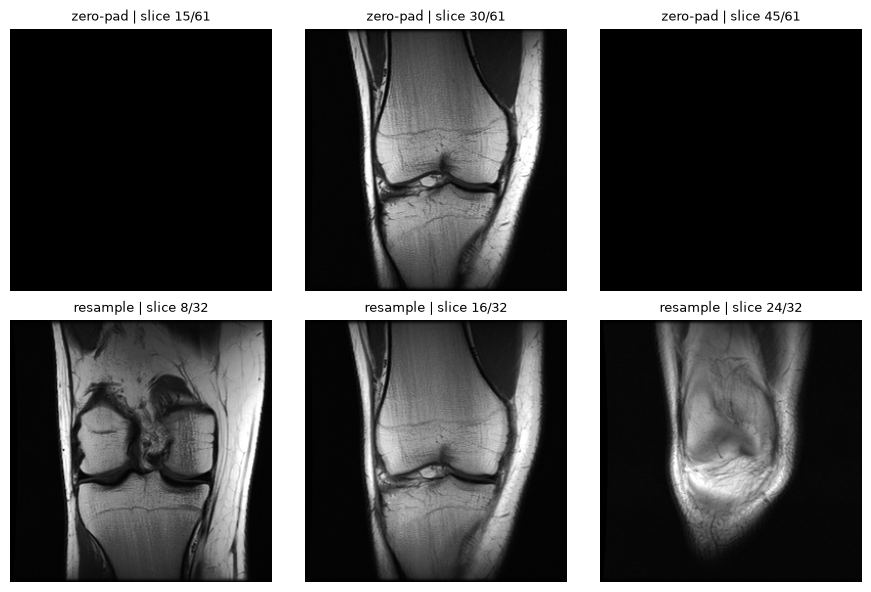

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(9, 6))
raw = np.load(os.path.join(IMG_DIR, SHORTEST['split'], SHORTEST['plane'], SHORTEST['id'] + '.npy'))
for row, (label, vol) in enumerate((('zero-pad', preprocess(raw, 'pad', PAD_TARGET)),
                                    ('resample', preprocess(raw, 'resample', TARGET_SLICES)))):
    d = vol.shape[1]
    for col, frac in enumerate((0.25, 0.5, 0.75)):
        ax = axes[row, col]
        ax.imshow(vol[0, int(d * frac)], cmap='gray')
        ax.set_title(f'{label} | slice {int(d * frac)}/{d}', fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.show()

## MRNetDataset

- Labels come from `{split}-{task}.csv`; class imbalance exposed as `pos_weight = neg/pos` for `BCEWithLogitsLoss`
- `strategy` switches between `'resample'` (fixed 32 slices) and `'pad'` (zero-padded to `target`)

In [6]:
class MRNetDataset(Dataset):
    def __init__(self, root=IMG_DIR, task='abnormal', split='train', plane='sagittal',
                 strategy='resample', target=None, transform=None):
        self.folder = os.path.join(root, split, plane)
        df = pd.read_csv(os.path.join(root, f'{split}-{task}.csv'),
                         header=None, names=['id', 'label'])
        df['id'] = df['id'].astype(int).astype(str).str.zfill(4)
        self.ids = df['id'].tolist()
        self.labels = df['label'].astype(np.float32).tolist()
        self.strategy = strategy
        self.target = target
        self.transform = transform
        pos, neg = sum(self.labels), len(self.labels) - sum(self.labels)
        self.weights = torch.tensor([1.0, neg / max(pos, 1.0)])

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, idx):
        arr = np.load(os.path.join(self.folder, self.ids[idx] + '.npy'))
        vol = preprocess(arr, self.strategy, self.target)
        if self.transform is not None:
            vol = self.transform(vol)
        return vol, torch.tensor(self.labels[idx])


class RandomHFlip:
    def __call__(self, vol):
        return torch.flip(vol, dims=[-1]) if torch.rand(1).item() < 0.5 else vol

In [7]:
train_ds = MRNetDataset(task='acl', split='train', plane='sagittal',
                        strategy='resample', transform=RandomHFlip())
valid_ds = MRNetDataset(task='acl', split='valid', plane='sagittal', strategy='resample')
train_loader = DataLoader(train_ds, batch_size=4, shuffle=True, num_workers=0, pin_memory=True)

x, y = next(iter(train_loader))
print('batch:', tuple(x.shape), x.dtype, '| labels:', y.tolist())
print('per-sample mean/std:', x.mean(dim=(1, 2, 3, 4)).numpy().round(3),
      x.std(dim=(1, 2, 3, 4)).numpy().round(3))
print('pos_weight:', train_ds.weights.tolist(), '| train/valid sizes:', len(train_ds), len(valid_ds))

batch: (4, 3, 32, 256, 256) torch.float32 | labels: [1.0, 0.0, 0.0, 1.0]
per-sample mean/std: [-0.  0. -0. -0.] [0.967 0.939 0.958 0.951]
pos_weight: [1.0, 4.432692527770996] | train/valid sizes: 1130 120


In [8]:
for task in TASKS:
    for split in ('train', 'valid'):
        ds = MRNetDataset(task=task, split=split, plane='axial', strategy='resample')
        labels = torch.tensor(ds.labels)
        print(f'{task:9s} {split:5s} n={len(ds):4d} positives={labels.sum().int().item():3d} '
              f'pos_weight={ds.weights[1].item():.2f}')

abnormal  train n=1130 positives=913 pos_weight=0.24
abnormal  valid n= 120 positives= 95 pos_weight=0.26
acl       train n=1130 positives=208 pos_weight=4.43
acl       valid n= 120 positives= 54 pos_weight=1.22
meniscus  train n=1130 positives=397 pos_weight=1.85
meniscus  valid n= 120 positives= 52 pos_weight=1.31


In [9]:
for strategy in ('resample', 'pad'):
    ds = MRNetDataset(task='abnormal', split='valid', plane='sagittal', strategy=strategy,
                      target=PAD_TARGET if strategy == 'pad' else TARGET_SLICES)
    dl = DataLoader(ds, batch_size=4, num_workers=0)
    t0 = time.time()
    for x, y in dl:
        pass
    print(f'{strategy:9s} batch={tuple(x.shape)} {len(ds)} samples in {time.time() - t0:.1f}s')

resample  batch=(4, 3, 32, 256, 256) 120 samples in 4.1s
pad       batch=(4, 3, 61, 256, 256) 120 samples in 4.5s


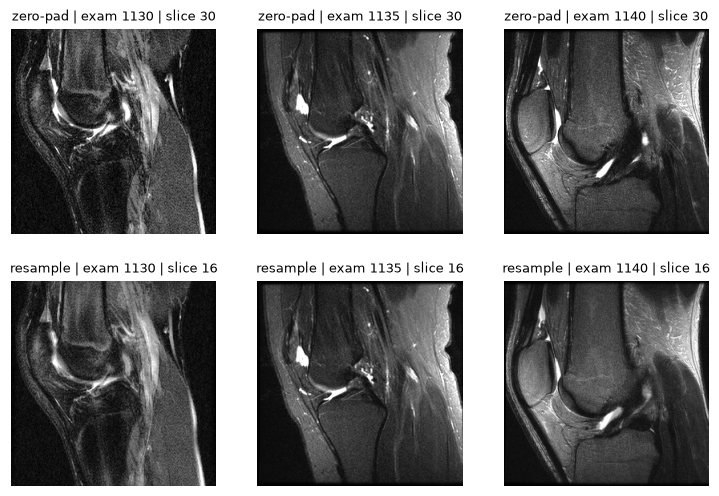

: 

In [ ]:
ds_pad = MRNetDataset(split='valid', plane='sagittal', strategy='pad', target=PAD_TARGET)
ds_res = MRNetDataset(split='valid', plane='sagittal', strategy='resample', target=TARGET_SLICES)

fig, axes = plt.subplots(2, 3, figsize=(9, 6))
for col, idx in enumerate((0, 5, 10)):
    for row, (name, ds) in enumerate((('zero-pad', ds_pad), ('resample', ds_res))):
        vol, _ = ds[idx]
        mid = vol.shape[1] // 2
        ax = axes[row, col]
        ax.imshow(vol[0, mid], cmap='gray')
        ax.set_title(f'{name} | exam {ds.ids[idx]} | slice {mid}', fontsize=9)
        ax.axis('off')
# plt.tight_layout()
plt.show()

Ready for Training <br> Lets gooooooooooooooooooooooo